# 1. Data Exploration

## Imports

In [349]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pycountry

data_path = "../data/raw/"

## Dataset loading

In [350]:
# WHO - Physical activity
who_physical_activity = pd.read_csv(
    data_path + "who/who_physical_activity.csv"
)

# Eurostat - Obesity
with open(
    data_path + "eurostat/eurostat_obesity.json",
    encoding="utf-8"
) as file:
    obesity_json = json.load(file)

# Eurostat - GDP per capita
with open(
    data_path + "eurostat/eurostat_gdp_2022.json",
    encoding="utf-8"
) as file:
    gdp_json = json.load(file)

## Data Dictionary   

This section describes the variables available in each dataset,
their meaning, units of measurement, and relevance to the analysis.

### 1. WHO – Physical Activity

| Column | Description | Unit / Values | Relevance |
|---|---|---|---|
| `Id` | Unique identifier of the observation | Numeric identifier | Technical identification |
| `IndicatorCode` | WHO indicator code | `NCD_PAA` | Identifies the physical inactivity indicator |
| `SpatialDimType` | Type of geographic dimension | Country, etc. | Identifies the geographic level |
| `SpatialDim` | Geographic identifier | ISO alpha-3 geographic identifier (e.g. `BGR`) | Used to match countries across datasets |
| `ParentLocationCode` | Code of the parent geographic region | WHO region code | Provides regional context |
| `ParentLocation` | Name of the parent geographic region | Region name | Provides regional context |
| `TimeDimType` | Type of time dimension | Year | Identifies the time dimension |
| `TimeDim` | Observation year | Year (e.g. `2022`) | Used to filter the analysis period |
| `Dim1Type` | Type of first disaggregation dimension | Sex | Identifies the population group |
| `Dim1` | Sex category | SEX_FMLE, SEX_MLE, SEX_BTSX | Used to select the overall adult population |
| `Dim2Type` | Type of second disaggregation dimension | Age | Identifies the age dimension |
| `Dim2` | 	Age-group category code | AGEGROUP_YEARS18-PLUS, AGEGROUP_YEARS60-69, etc. | Used to select adults aged 18+ |
| `Dim3Type` | Type of third disaggregation dimension | Not populated | Not used in this analysis |
| `Dim3` | Third disaggregation category | Not populated | Not used in this analysis |
| `DataSourceDimType` | Type of data-source dimension | Not populated | Not used in this analysis |
| `DataSourceDim` | Data-source dimension value | Not populated | Not used in this analysis |
| `Value` | Formatted prevalence estimate including uncertainty interval | Percentage and uncertainty interval | Human-readable result |
| `NumericValue` | Numerical estimate of physical inactivity prevalence | Percentage (%) | Main variable for the analysis |
| `Low` | Lower bound of the uncertainty interval | Percentage (%) | Indicates uncertainty around the estimate |
| `High` | Upper bound of the uncertainty interval | Percentage (%) | Indicates uncertainty around the estimate |
| `Comments` | Additional information about the observation | Text | Supplementary context |
| `Date` | Date associated with the observation | Date | Metadata |
| `TimeDimensionValue` | Time dimension value | Year | Alternative time representation |
| `TimeDimensionBegin` | Beginning of the time period | Date | Metadata |
| `TimeDimensionEnd` | End of the time period | Date | Metadata |

# 2. Initial Data Inspection

The purpose of this stage is to understand the structure, content, and quality of the datasets before performing any transformations or statistical analysis.

We will inspect:

- Dataset dimensions and column names.
- Data types and missing values.
- Available geographical locations and time periods.
- Population dimensions and indicator definitions.
- Potential inconsistencies that may affect the analysis.

## 2.1 WHO Physical Activity

### Dataset size and structure

The WHO dataset contains estimates of insufficient physical activity among adults aged 18 and above. It includes observations across multiple countries, years, genders, and age groups.

The initial exploration will help us identify the appropriate population categories and geographical coverage for our analysis.

In [351]:
# records and columns in the dataset
who_physical_activity.shape

(41262, 25)

In [352]:
who_physical_activity.head(5)

,Id,IndicatorCode,SpatialDimType,SpatialDim,ParentLocationCode,TimeDimType,ParentLocation,Dim1Type,TimeDim,Dim1,...,DataSourceDim,Value,NumericValue,Low,High,Comments,Date,TimeDimensionValue,TimeDimensionBegin,TimeDimensionEnd
0,27,NCD_PAA,COUNTRY,KNA,AMR,YEAR,Americas,SEX,2015,SEX_BTSX,...,NaN,38.6 [24.0-53.8],38.649147,24.015909,53.761047,NaN,2024-06-21T13:42:48.827+02:00,2015,2015-01-01T00:00:00+01:00,2015-12-31T00:00:00+01:00
1,551,NCD_PAA,COUNTRY,WSM,WPR,YEAR,Western Pacific,SEX,2007,SEX_BTSX,...,NaN,28.9 [22.9-35.3],28.883972,22.874971,35.296017,NaN,2024-06-21T13:42:48.827+02:00,2007,2007-01-01T00:00:00+01:00,2007-12-31T00:00:00+01:00
2,2450,NCD_PAA,COUNTRY,JPN,WPR,YEAR,Western Pacific,SEX,2006,SEX_MLE,...,NaN,29.5 [13.7-50.6],29.484329,13.722679,50.564968,NaN,2024-06-21T13:42:48.827+02:00,2006,2006-01-01T00:00:00+01:00,2006-12-31T00:00:00+01:00
3,2470,NCD_PAA,GLOBAL,GLOBAL,NaN,YEAR,NaN,SEX,2002,SEX_MLE,...,NaN,21.5 [18.7-24.7],21.511904,18.698532,24.674263,NaN,2024-06-21T13:42:48.827+02:00,2002,2002-01-01T00:00:00+01:00,2002-12-31T00:00:00+01:00
4,2512,NCD_PAA,COUNTRY,SDN,EMR,YEAR,Eastern Mediterranean,SEX,2006,SEX_FMLE,...,NaN,24.6 [10.8-42.5],24.585480,10.847883,42.450493,NaN,2024-06-21T13:42:48.827+02:00,2006,2006-01-01T00:00:00+01:00,2006-12-31T00:00:00+01:00


In [353]:
#understanding general info for our WHO dataset
who_physical_activity.info()

<class 'pandas.DataFrame'>
RangeIndex: 41262 entries, 0 to 41261
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  41262 non-null  int64  
 1   IndicatorCode       41262 non-null  str    
 2   SpatialDimType      41262 non-null  str    
 3   SpatialDim          41262 non-null  str    
 4   ParentLocationCode  40503 non-null  str    
 5   TimeDimType         41262 non-null  str    
 6   ParentLocation      40503 non-null  str    
 7   Dim1Type            41262 non-null  str    
 8   TimeDim             41262 non-null  int64  
 9   Dim1                41262 non-null  str    
 10  Dim2Type            41262 non-null  str    
 11  Dim2                41262 non-null  str    
 12  Dim3Type            0 non-null      float64
 13  Dim3                0 non-null      float64
 14  DataSourceDimType   0 non-null      float64
 15  DataSourceDim       0 non-null      float64
 16  Value          

### Missing Values

In [354]:
# checking for null values
who_physical_activity.isnull().sum()

Id                        0
IndicatorCode             0
SpatialDimType            0
SpatialDim                0
ParentLocationCode      759
TimeDimType               0
ParentLocation          759
Dim1Type                  0
TimeDim                   0
Dim1                      0
Dim2Type                  0
Dim2                      0
Dim3Type              41262
Dim3                  41262
DataSourceDimType     41262
DataSourceDim         41262
Value                     0
NumericValue              0
Low                       0
High                      0
Comments              41193
Date                      0
TimeDimensionValue        0
TimeDimensionBegin        0
TimeDimensionEnd          0
dtype: int64


The WHO dataset contains missing values in several columns.

The columns `Dim3Type`, `Dim3`, `DataSourceDimType`, and
`DataSourceDim` are entirely empty in the current dataset.
The `Comments` column is also mostly empty.

The missing values in `ParentLocation` and `ParentLocationCode`
are associated with observations that do not have an assigned
parent region, such as global-level observations.

These columns are not required for our planned analysis.
The main analytical variables, including `SpatialDim`,
`TimeDim`, `Dim1`, `Dim2`, and `NumericValue`, contain no
missing values.

### Geographic Identifiers

In [355]:

# Inspect geographical identifiers and names
who_physical_activity[
    ["SpatialDim", "SpatialDimType", "ParentLocation"]
].drop_duplicates().sort_values("SpatialDim")

,SpatialDim,SpatialDimType,ParentLocation
80,AFG,COUNTRY,Eastern Mediterranean
54,AFR,REGION,NaN
40,AGO,COUNTRY,Africa
93,ALB,COUNTRY,Europe
27318,AMR,REGION,NaN
...,...,...,...
1,WSM,COUNTRY,Western Pacific
2628,YEM,COUNTRY,Eastern Mediterranean
64,ZAF,COUNTRY,Africa
2641,ZMB,COUNTRY,Africa


### Sex and age categories

In [356]:
# Inspect sex categories 

who_physical_activity["Dim1"].value_counts()

Dim1
SEX_MLE     18262
SEX_FMLE    18262
SEX_BTSX     4738
Name: count, dtype: int64

In [357]:
# Inspect age categories

who_physical_activity["Dim2"].value_counts()

Dim2
AGEGROUP_YEARS18-PLUS    14214
AGEGROUP_YEARS80PLUS      9016
AGEGROUP_YEARS70-79       9016
AGEGROUP_YEARS60-69       9016
Name: count, dtype: int64

### Raw 2022 observations

In [358]:
who_physical_activity[
    who_physical_activity["TimeDim"] == 2022
][["SpatialDim", "Dim1", "Dim2","NumericValue", "Value"]].head(20)

,SpatialDim,Dim1,Dim2,NumericValue,Value
28,COK,SEX_BTSX,AGEGROUP_YEARS18-PLUS,25.422981,25.4 [18.2-33.7]
50,ARE,SEX_MLE,AGEGROUP_YEARS18-PLUS,63.121742,63.1 [47.7-76.9]
63,COD,SEX_BTSX,AGEGROUP_YEARS18-PLUS,14.868432,14.9 [4.3-31.0]
92,AFG,SEX_FMLE,AGEGROUP_YEARS80PLUS,87.410247,87.4 [76.3-98.5]
105,ALB,SEX_FMLE,AGEGROUP_YEARS80PLUS,60.144997,60.1 [23.7-96.5]
119,DZA,SEX_FMLE,AGEGROUP_YEARS80PLUS,80.607128,80.6 [65.7-95.5]
132,AND,SEX_FMLE,AGEGROUP_YEARS80PLUS,60.499376,60.5 [28.3-92.7]
147,AGO,SEX_FMLE,AGEGROUP_YEARS80PLUS,53.295499,53.3 [16.7-89.9]
157,ATG,SEX_FMLE,AGEGROUP_YEARS80PLUS,74.319124,74.3 [43.8-100.0]
171,ARG,SEX_FMLE,AGEGROUP_YEARS80PLUS,72.612000,72.6 [57.5-87.7]


## 2.2 Eurostat Obesity

### JSON structure

The Eurostat obesity dataset is provided in JSON-stat format rather than
as a traditional table.

JSON-stat stores observations in a compact structure:
- `id` identifies the dataset dimensions.
- `size` defines the number of categories in each dimension.
- `dimension` contains the category codes and their labels.
- `value` contains the actual observations, stored using flat indexes.
- `status` contains flags describing the reliability or status of observations.

For this project, we are interested in the percentage of adults classified
as obese (`BMI_GE30`) in 2022.

In [359]:
# Inspect the top-level structure
obesity_json.keys()

dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])

### Dimensions and categories

In [360]:
# Inspect the dimensions and their sizes
print("Dimensions:", obesity_json["id"])
print("Dimension sizes:", obesity_json["size"])

Dimensions: ['freq', 'unit', 'bmi', 'geo', 'time']
Dimension sizes: [1, 1, 3, 40, 1]


In [361]:
# Inspect the categories available in each dimension
for dimension in obesity_json["id"]:
    dimension_info = obesity_json["dimension"][dimension]

    print(f"\nDimension: {dimension}")
    print("Description:", dimension_info["label"])
    print("Categories:", dimension_info["category"]["index"])
    print("Labels:", dimension_info["category"].get("label", {}))


Dimension: freq
Description: Time frequency
Categories: {'A': 0}
Labels: {'A': 'Annual'}

Dimension: unit
Description: Unit of measure
Categories: {'PC': 0}
Labels: {'PC': 'Percentage'}

Dimension: bmi
Description: Body Mass Index
Categories: {'BMI_GE25': 0, 'BMI25-29': 1, 'BMI_GE30': 2}
Labels: {'BMI_GE25': 'Overweight', 'BMI25-29': 'Pre-obese', 'BMI_GE30': 'Obese'}

Dimension: geo
Description: Geopolitical entity (reporting)
Categories: {'EU27_2020': 0, 'EA21': 1, 'EA20': 2, 'BE': 3, 'BG': 4, 'CZ': 5, 'DK': 6, 'DE': 7, 'EE': 8, 'IE': 9, 'EL': 10, 'ES': 11, 'FR': 12, 'HR': 13, 'IT': 14, 'CY': 15, 'LV': 16, 'LT': 17, 'LU': 18, 'HU': 19, 'MT': 20, 'NL': 21, 'AT': 22, 'PL': 23, 'PT': 24, 'RO': 25, 'SI': 26, 'SK': 27, 'FI': 28, 'SE': 29, 'IS': 30, 'NO': 31, 'CH': 32, 'AL': 33, 'BA': 34, 'ME': 35, 'MK': 36, 'RS': 37, 'TR': 38, 'UK': 39}
Labels: {'EU27_2020': 'European Union - 27 countries (from 2020)', 'EA21': 'Euro area – 21 countries (from 2026)', 'EA20': 'Euro area – 20 countries (2023

### Understanding the Flat Index

JSON-stat stores observations using a single flat index.

The index represents a position across all dataset dimensions.
Because the dimensions have a fixed order, we can calculate the
position of each category using the dimension sizes.

In this dataset, `freq`, `unit`, and `time` each have only one
category. Therefore, the flat index can be calculated as:

`flat_index = bmi_position * number_of_geographies + geo_position`

We can use this formula to identify which country and BMI category
each observation belongs to.

In [362]:
# Get the category indexes
bmi_index = obesity_json["dimension"]["bmi"]["category"]["index"]
geo_index = obesity_json["dimension"]["geo"]["category"]["index"]

print("BMI categories:", bmi_index)
print("Geography categories:", geo_index)

BMI categories: {'BMI_GE25': 0, 'BMI25-29': 1, 'BMI_GE30': 2}
Geography categories: {'EU27_2020': 0, 'EA21': 1, 'EA20': 2, 'BE': 3, 'BG': 4, 'CZ': 5, 'DK': 6, 'DE': 7, 'EE': 8, 'IE': 9, 'EL': 10, 'ES': 11, 'FR': 12, 'HR': 13, 'IT': 14, 'CY': 15, 'LV': 16, 'LT': 17, 'LU': 18, 'HU': 19, 'MT': 20, 'NL': 21, 'AT': 22, 'PL': 23, 'PT': 24, 'RO': 25, 'SI': 26, 'SK': 27, 'FI': 28, 'SE': 29, 'IS': 30, 'NO': 31, 'CH': 32, 'AL': 33, 'BA': 34, 'ME': 35, 'MK': 36, 'RS': 37, 'TR': 38, 'UK': 39}


## 2.3 Eurostat GDP per capita
### JSON Structure

The Eurostat GDP per capita dataset is provided in JSON-stat format rather than as a traditional table.

JSON-stat stores data in a structured format containing metadata, dimensions, category information, numerical observations, and data quality flags.

Before extracting the GDP per capita observations, we will inspect the structure of the JSON file to understand how the data is organized and how the observations are represented.


In [363]:
gdp_json.keys()

dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])

### Dimensions and categories


In [364]:
# Inspect the dimensions and their sizes
print("Dimensions:", gdp_json["id"])
print("Dimension sizes:", gdp_json["size"])

Dimensions: ['freq', 'unit', 'na_item', 'geo', 'time']
Dimension sizes: [1, 1, 1, 45, 1]


In [365]:
# Inspect the categories available in each dimension
for dimension in gdp_json["id"]:
    dimension_info = gdp_json["dimension"][dimension]

    print(f"\nDimension: {dimension}")
    print("Description:", dimension_info["label"])
    print("Categories:", dimension_info["category"]["index"])
    print("Labels:", dimension_info["category"].get("label", {}))


Dimension: freq
Description: Time frequency
Categories: {'A': 0}
Labels: {'A': 'Annual'}

Dimension: unit
Description: Unit of measure
Categories: {'CP_EUR_HAB': 0}
Labels: {'CP_EUR_HAB': 'Current prices, euro per capita'}

Dimension: na_item
Description: National accounts indicator (ESA 2010)
Categories: {'B1GQ': 0}
Labels: {'B1GQ': 'Gross domestic product at market prices'}

Dimension: geo
Description: Geopolitical entity (reporting)
Categories: {'EU27_2020': 0, 'EA': 1, 'EA21': 2, 'EA20': 3, 'EA19': 4, 'EA12': 5, 'BE': 6, 'BG': 7, 'CZ': 8, 'DK': 9, 'DE': 10, 'EE': 11, 'IE': 12, 'EL': 13, 'ES': 14, 'FR': 15, 'HR': 16, 'IT': 17, 'CY': 18, 'LV': 19, 'LT': 20, 'LU': 21, 'HU': 22, 'MT': 23, 'NL': 24, 'AT': 25, 'PL': 26, 'PT': 27, 'RO': 28, 'SI': 29, 'SK': 30, 'FI': 31, 'SE': 32, 'IS': 33, 'LI': 34, 'NO': 35, 'CH': 36, 'BA': 37, 'ME': 38, 'MD': 39, 'MK': 40, 'AL': 41, 'RS': 42, 'TR': 43, 'XK': 44}
Labels: {'EU27_2020': 'European Union - 27 countries (from 2020)', 'EA': 'Euro area (EA11-1

### Understanding the GDP Indicator

The dataset measures Gross Domestic Product (GDP) at market prices (B1GQ), expressed in current euros per capita (CP_EUR_HAB).

GDP per capita represents the economic output of a country relative to its population. It is calculated by dividing total GDP by the population.

Since the data is expressed in current euros, it is not adjusted for differences in purchasing power between countries or changes in prices over time. This should be taken into consideration when interpreting and comparing the values.

### Geographical Coverage

The geographical dimension (geo) contains 45 entries. These include individual countries as well as geographical aggregates, such as the European Union and different configurations of the Euro area.

The dataset also includes non-EU European countries and other geographical entities. Therefore, the geographical dimension does not consist exclusively of EU member states.

This distinction will be important during data preparation, when we will identify and exclude geographical aggregates to create a dataset containing individual countries only.

# 3. Data Preparation
## 3.1 WHO Physical Activity
### Selecting relevant population

The WHO dataset contains separate estimates by gender and age group. To ensure consistency with our research objective, we will use observations representing both sexes and the overall adult population aged 18 years and above.

We will initially focus on the year 2022 to align the physical inactivity indicator with the obesity and GDP datasets.

Only country-level observations are retained because the unit of analysis in this project is the individual European country. Regional and global aggregates will not be included in the country-level statistical analysis.

### Filtering 2022 / adults / both sexes / countries

In [366]:
# Select 2022 observations for both sexes and adults aged 18+
who_2022_adults = who_physical_activity[
    (who_physical_activity["TimeDim"] == 2022) &
    (who_physical_activity["Dim1"] == "SEX_BTSX") &
    (who_physical_activity["Dim2"] == "AGEGROUP_YEARS18-PLUS") &
    (who_physical_activity["SpatialDimType"] == "COUNTRY")
].copy()

who_2022_adults.shape

(195, 25)

In [367]:
who_2022_adults[
    ["SpatialDim", "TimeDim", "Value", "Low", "High"]
].head(10)

,SpatialDim,TimeDim,Value,Low,High
28,COK,2022,25.4 [18.2-33.7],18.174231,33.713932
63,COD,2022,14.9 [4.3-31.0],4.344076,30.958775
27145,MOZ,2022,9.7 [2.7-22.1],2.726537,22.053137
27186,HUN,2022,29.4 [22.2-37.3],22.200769,37.267242
27272,LBY,2022,45.6 [36.5-54.5],36.542236,54.466022
27489,VNM,2022,30.3 [23.0-38.1],23.002514,38.103638
27690,TUR,2022,44.4 [32.4-56.7],32.352913,56.661461
28030,KIR,2022,31.9 [20.1-44.2],20.144764,44.226540
28049,FSM,2022,29.3 [15.8-45.4],15.788227,45.438564
28053,SWZ,2022,19.2 [10.1-30.7],10.094573,30.733103


### "Validation of 195 country observations

In [368]:
#check number of unique geographic locations
who_2022_adults["SpatialDim"].nunique()

195

In [369]:
#check if a geographic location appears more than once
who_2022_adults.duplicated(
    subset=["SpatialDim"]
).sum()

np.int64(0)

The WHO dataset was filtered to include observations for 2022, both sexes, and adults aged 18 years and above.

This produced 195 geographical observations, representing 195 unique locations. The original dataset covers countries worldwide, so further geographical filtering will be required to restrict the analysis to European countries.

The selected indicator is the estimated prevalence of insufficient physical activity, expressed as a percentage. The dataset also provides lower and upper uncertainty bounds for each estimate.

### Descriptive statistics
The filtered WHO dataset contains 195 country-level observations for 2022, covering adults aged 18 and older, with estimates for both sexes combined.

The mean prevalence of insufficient physical activity across these countries is **27.30%**, while the median is **25.42%**. The mean being slightly higher than the median suggests that some countries with relatively high physical inactivity estimates influence the overall average.

The standard deviation is **12.84 percentage points**, indicating considerable variation in physical inactivity prevalence across countries.

The observed estimates range from **2.70% to 66.14%**. The middle 50% of observations fall between **17.67% and 36.77%**.

The `Low` and `High` columns represent the lower and upper uncertainty bounds associated with individual country estimates. They provide additional information about the uncertainty of the reported prevalence values.

These statistics describe the worldwide dataset. For our research questions, we will subsequently focus on European countries and compare physical inactivity with obesity prevalence and GDP per capita.


In [370]:
who_2022_adults[["NumericValue", "Low", "High"]].describe()

,NumericValue,Low,High
count,195.000000,195.000000,195.000000
mean,27.300079,17.055879,39.525549
std,12.838810,10.939727,15.434314
min,2.695235,1.116092,5.254488
25%,17.668948,8.871012,28.916632
50%,25.422981,14.820278,38.103638
75%,36.765958,23.022635,49.639677
max,66.137848,54.599983,79.739311


### Visualisations

To complement the descriptive statistics, we use a histogram
and a boxplot to examine the distribution of physical
inactivity prevalence across countries.

The histogram shows the frequency of different prevalence
values, while the boxplot highlights the median, spread,
and potential outliers.

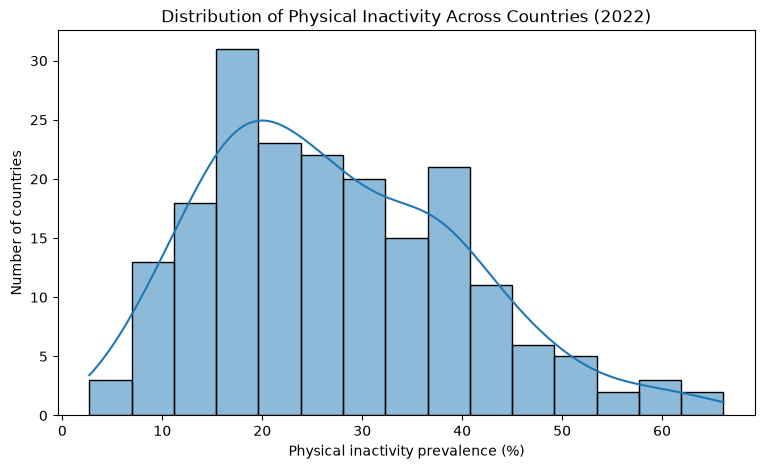

In [371]:
# Histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    data=who_2022_adults,
    x="NumericValue",
    bins=15,
    kde=True
)

plt.title("Distribution of Physical Inactivity Across Countries (2022)")
plt.xlabel("Physical inactivity prevalence (%)")
plt.ylabel("Number of countries")
plt.show()



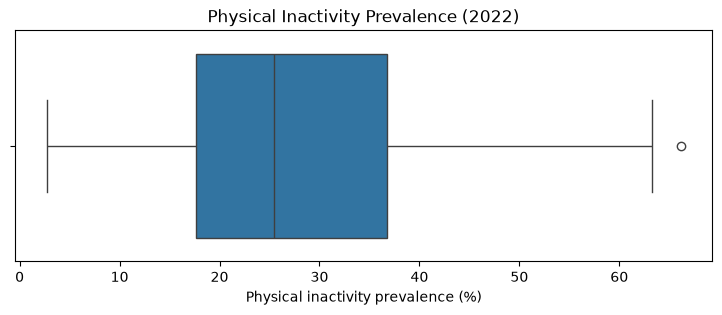

In [372]:
# Boxplot
plt.figure(figsize=(9, 3))

sns.boxplot(data=who_2022_adults, x="NumericValue")

plt.title("Physical Inactivity Prevalence (2022)")
plt.xlabel("Physical inactivity prevalence (%)")
plt.show()

## 3.2 Eurostat Obesity
### Extraction of obesity indicator

We only need the `BMI_GE30` category, representing the percentage
of adults classified as obese.

We will:
1. Identify the position of `BMI_GE30`.
2. Iterate through all geographical categories.
3. Calculate the flat index for each country.
4. Retrieve the corresponding observation and status flag.
5. Store the results in a Pandas DataFrame.

In [373]:
# Get the position of the obesity category
obese_position = bmi_index["BMI_GE30"]

# Reverse the geography index: position -> country code
geo_codes = {position: code for code, position in geo_index.items()}

#Extract obesity observations
obesity_data = []

number_of_geographies = len(geo_index)


for geo_position, country_code in geo_codes.items():

    flat_index = obese_position * number_of_geographies + geo_position

    value = obesity_json["value"].get(str(flat_index))
    status = obesity_json.get("status", {}).get(str(flat_index))

    if value is not None:
        obesity_data.append({
            "geo": country_code,
            "obesity_pct": value,
            "status": status
        })

obesity_df = pd.DataFrame(obesity_data)

### Initial extracted dataset validation

Before excluding geographical aggregates, we will inspect the extracted dataset to verify that the data has been retrieved correctly.

This initial validation focuses on:
- The number of observations and columns.
- Data types and the presence of missing values.
- The range of geographical codes included in the dataset.
- The highest obesity prevalence estimates.

This helps identify potential issues with the extraction process before preparing the country-level dataset for further analysis.

In [374]:
obesity_df.shape

(37, 3)

In [375]:
obesity_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   geo          37 non-null     str    
 1   obesity_pct  37 non-null     float64
 2   status       6 non-null      str    
dtypes: float64(1), str(2)
memory usage: 1020.0 bytes


In [376]:
obesity_df.isnull().sum()

geo             0
obesity_pct     0
status         31
dtype: int64

In [377]:
obesity_df.sort_values("obesity_pct", ascending=False).head(10)

,geo,obesity_pct,status
18,MT,26.1,NaN
28,IS,24.2,NaN
14,LV,23.3,NaN
17,HU,22.2,NaN
6,EE,22.1,NaN
26,FI,21.2,NaN
15,LT,20.6,u
36,TR,20.1,NaN
7,IE,19.8,u
5,DK,19.0,NaN


In [378]:
obesity_df["geo"].sort_values().tolist()

['AL',
 'AT',
 'BA',
 'BE',
 'BG',
 'CH',
 'CY',
 'CZ',
 'DK',
 'EA20',
 'EE',
 'EL',
 'ES',
 'EU27_2020',
 'FI',
 'FR',
 'HR',
 'HU',
 'IE',
 'IS',
 'IT',
 'LT',
 'LU',
 'LV',
 'ME',
 'MK',
 'MT',
 'NL',
 'NO',
 'PL',
 'PT',
 'RO',
 'RS',
 'SE',
 'SI',
 'SK',
 'TR']

### Excluding aggregates

The Eurostat dataset includes both individual countries and geographical aggregates, such as the European Union and the Euro area.

Since our analysis will treat each country as an individual observation, including these aggregates alongside individual countries could distort the statistical analysis and create overlapping geographical observations.

We therefore exclude the Euro area (`EA20`) and European Union (`EU27_2020`) from the country-level dataset.

The resulting dataset will contain individual countries only.

In [379]:
# Exclude geographical aggregates
obesity_aggregates = ["EA20", "EU27_2020"]

obesity_countries = obesity_df[
    ~obesity_df["geo"].isin(obesity_aggregates)
].copy()

In [380]:
obesity_countries.shape

(35, 3)

In [381]:
obesity_countries["geo"].sort_values().tolist()

['AL',
 'AT',
 'BA',
 'BE',
 'BG',
 'CH',
 'CY',
 'CZ',
 'DK',
 'EE',
 'EL',
 'ES',
 'FI',
 'FR',
 'HR',
 'HU',
 'IE',
 'IS',
 'IT',
 'LT',
 'LU',
 'LV',
 'ME',
 'MK',
 'MT',
 'NL',
 'NO',
 'PL',
 'PT',
 'RO',
 'RS',
 'SE',
 'SI',
 'SK',
 'TR']

The extracted Eurostat dataset contains 35 individual countries with available obesity prevalence data for 2022, after excluding two geographical aggregates (Euro area and European Union).

The highest observed prevalence is in Malta (26.1%), followed by Iceland (24.2%) and Latvia (23.3%).

Some observations carry reliability flags. These flags are retained for further data-quality assessment rather than being removed at this stage.

These are preliminary descriptive findings. Further validation of data quality and geographical coverage, as well as integration with the physical activity dataset, is required before drawing conclusions.

### Reliability flags

In [382]:
obesity_countries["status"].value_counts(dropna=False)

status
NaN    31
u       4
Name: count, dtype: int64

The Eurostat dataset includes status flags that provide additional information about individual observations.

The extracted data contains the following flags:

- `u` – Low reliability
- `e` – Estimated value
- No flag – No additional status flag is provided for the observation.

These flags are retained in the extracted dataset so that data quality can be considered during subsequent analysis.

The absence of a status flag does not indicate a missing observation.

After excluding geographical aggregates, the country-level dataset contains 35 observations. Four observations are marked as low reliability (u), while the remaining 31 observations have no additional status flag.

No observations marked as estimated (e) remain in the filtered country-level dataset.

### Descriptive statistics

In [383]:
obesity_countries["obesity_pct"].describe()

count    35.000000
mean     16.557143
std       4.413168
min       7.100000
25%      13.500000
50%      16.700000
75%      19.400000
max      26.100000
Name: obesity_pct, dtype: float64

The filtered obesity dataset contains 35 individual countries with available obesity prevalence data for 2022.

The mean obesity prevalence is 16.56%, while the median is 16.70%. The relatively small difference between these two measures suggests that the central tendency of the distribution is similar when measured using the mean and median. However, this alone is not sufficient to determine the shape or symmetry of the distribution.

The standard deviation is 4.41 percentage points, indicating variation in obesity prevalence across the included countries.

The observed values range from 7.10% to 26.10%. The middle 50% of observations fall between 13.50% and 19.40%.

These statistics provide an overview of obesity prevalence across the selected countries. They do not yet tell us whether obesity is associated with physical inactivity or economic development. Those relationships will be examined during the statistical analysis stage.

### Visualisations 

Visualisations provide a complementary view of the distribution of obesity prevalence across the selected countries.

The histogram helps us understand how observations are distributed across different prevalence levels, while the boxplot provides a summary of the distribution, including its median, spread, and potential outliers.

Both visualisations use the filtered country-level dataset, excluding the European Union and Euro area aggregates.

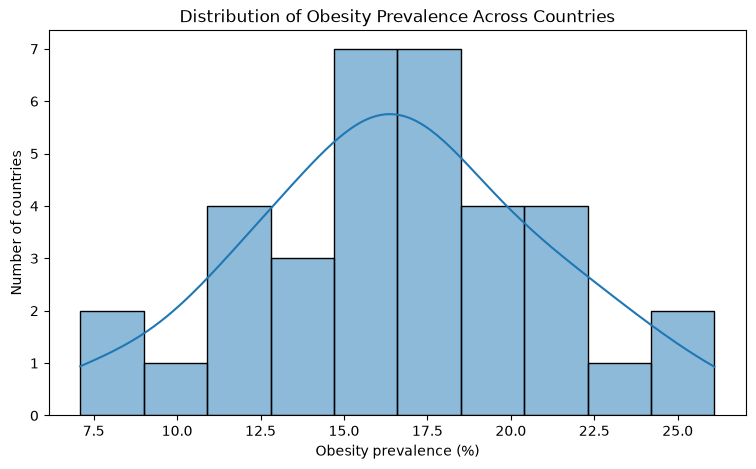

In [384]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=obesity_countries,
    x="obesity_pct",
    bins=10,
    kde=True
)

plt.title("Distribution of Obesity Prevalence Across Countries")
plt.xlabel("Obesity prevalence (%)")
plt.ylabel("Number of countries")

plt.show()

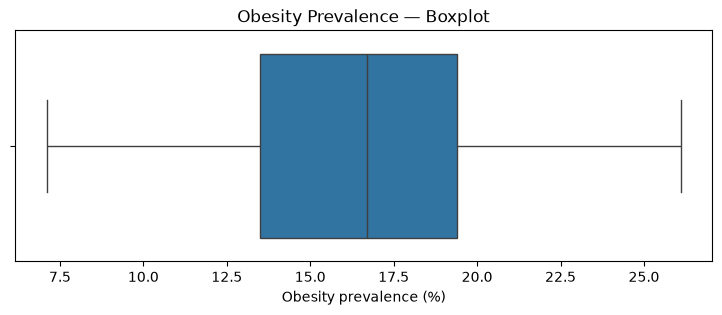

In [385]:
plt.figure(figsize=(9, 3))

sns.boxplot(
    data=obesity_countries,
    x="obesity_pct"
)

plt.title("Obesity Prevalence — Boxplot")
plt.xlabel("Obesity prevalence (%)")

plt.show()

## 3.3 Eurostat GDP per capita

### Extracting GDP per capita observations

The GDP dataset contains one observation for each geographical entity for the selected reference year and measurement unit.

Since the frequency, unit, national accounts indicator, and reference year dimensions each contain only one category, the extraction focuses on the geographical dimension (`geo`).

We will convert the JSON-stat structure into a Pandas DataFrame containing the geographical code, GDP per capita value, and any available data quality status flag.

In [386]:
# Extract GDP per capita observations
geo_index = gdp_json["dimension"]["geo"]["category"]["index"]

# Reverse the geographical index to map positions to country codes
geo_codes = {
    position: code
    for code, position in geo_index.items()
}

gdp_data = []

for geo_position, country_code in geo_codes.items():

    value = gdp_json["value"].get(str(geo_position))
    status = gdp_json.get("status", {}).get(str(geo_position))

    if value is not None:
        gdp_data.append({
            "geo": country_code,
            "gdp_per_capita": value,
            "status": status
        })

gdp_df = pd.DataFrame(gdp_data)

In [387]:
gdp_df.head()

,geo,gdp_per_capita,status
0,EU27_2020,36190,NaN
1,EA,39930,NaN
2,EA21,39200,NaN
3,EA20,39680,NaN
4,EA19,39930,NaN


### Initial extracted dataset validation

After extracting the GDP per capita observations from the JSON-stat dataset, we will perform an initial validation of the resulting DataFrame.

This step checks the dataset's dimensions, column data types, and the presence of missing values. It helps us verify that the extraction process produced a usable tabular structure before proceeding with further data preparation.

In [388]:
# Check dimensions
gdp_df.shape

(44, 3)

In [389]:
# Inspect column data types and non-null values
gdp_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   geo             44 non-null     str  
 1   gdp_per_capita  44 non-null     int64
 2   status          4 non-null      str  
dtypes: int64(1), str(2)
memory usage: 1.2 KB


In [390]:
# Check missing values
gdp_df.isnull().sum()

geo                0
gdp_per_capita     0
status            40
dtype: int64


The extraction produced a DataFrame containing 44 observations and three columns: geographical code, GDP per capita, and data quality status.

All 44 observations contain a geographical code and a numerical GDP per capita value. The GDP column is already stored as an integer data type, so no numerical type conversion is required at this stage.

The status column contains 40 missing values, meaning that no additional status flag is recorded for those observations. The remaining four observations have a status flag, which will be examined separately during data quality validation.

The original JSON contained 45 geographical entities, but only 44 had available numerical GDP observations. The geographical entity without an observation will be identified during the next validation steps.

#### Missing Geographical Observations

In [391]:
# Identify geographical entities without GDP observations
missing_geo = set(geo_index.keys()) - set(gdp_df["geo"])

missing_geo

{'XK'}

Comparing the geographical codes in the original JSON dataset with those extracted into the DataFrame revealed one geographical entity without an available GDP per capita observation: Kosovo (`XK`).

The original dataset contains 45 geographical entities, while the extracted DataFrame contains 44 observations.

Since no GDP value is available for Kosovo in the selected dataset and reference year, it cannot be included in the subsequent statistical analysis.

#### Duplicates Check

In [392]:
gdp_df["geo"].duplicated().sum()

np.int64(0)

The geographical code column contains no duplicate values.

This confirms that each geographical entity appears only once in the extracted dataset, which is expected since we have a single GDP per capita observation per entity for 2022.

### Reliability flags

In [393]:
gdp_df["status"].value_counts(dropna=False)

status
NaN    40
e       2
b       1
p       1
Name: count, dtype: int64

In [394]:
# Display observations with data quality flags
gdp_df[gdp_df["status"].notna()]

,geo,gdp_per_capita,status
26,PL,17520,b
33,IS,74980,p
40,MK,7710,e
41,AL,7360,e


The extracted GDP dataset contains four observations with additional data quality flags:

- Poland (`b`): Break in time series.
- Iceland (`p`): Provisional value.
- North Macedonia (`e`): Estimated value.
- Albania (`e`): Estimated value.

The remaining 40 observations have no additional status flag.

These flags provide important information about the reliability and comparability of the reported values. However, they do not indicate that the observations are missing.

For the initial analysis, all observations with available GDP values will be retained. The status flags will be preserved so that potential data quality limitations can be considered when interpreting the results.

### Excluding aggregates

In [395]:
# Display all geographical entities
gdp_df["geo"].tolist()

['EU27_2020',
 'EA',
 'EA21',
 'EA20',
 'EA19',
 'EA12',
 'BE',
 'BG',
 'CZ',
 'DK',
 'DE',
 'EE',
 'IE',
 'EL',
 'ES',
 'FR',
 'HR',
 'IT',
 'CY',
 'LV',
 'LT',
 'LU',
 'HU',
 'MT',
 'NL',
 'AT',
 'PL',
 'PT',
 'RO',
 'SI',
 'SK',
 'FI',
 'SE',
 'IS',
 'LI',
 'NO',
 'CH',
 'BA',
 'ME',
 'MD',
 'MK',
 'AL',
 'RS',
 'TR']

The extracted GDP dataset contains 44 geographical entities, including individual countries and geographical aggregates.

Six entries represent geographical aggregates:

- `EU27_2020` – European Union (27 countries)
- `EA` – Euro area
- `EA21` – Euro area (21 countries)
- `EA20` – Euro area (20 countries)
- `EA19` – Euro area (19 countries)
- `EA12` – Euro area (12 countries)

Since the analysis focuses on individual European countries, these aggregate observations will be excluded.

Including geographical aggregates alongside individual countries could introduce overlapping observations, as aggregate values already incorporate the economic output of multiple countries.

After excluding these six aggregates, the dataset will contain 38 individual countries with available GDP per capita observations.

In [396]:
# Remove geographical aggregates
gdp_aggregates = ["EU27_2020", "EA", "EA21", "EA20", "EA19", "EA12"]

gdp_countries = gdp_df[
    ~gdp_df["geo"].isin(gdp_aggregates)
].copy()

In [397]:
gdp_countries.shape

(38, 3)

In [398]:
gdp_countries.head()

,geo,gdp_per_capita,status
6,BE,48090,NaN
7,BG,13350,NaN
8,CZ,26670,NaN
9,DK,64430,NaN
10,DE,48600,NaN


In [414]:
gdp_countries["geo"].isin(gdp_aggregates).sum()

np.int64(0)

In [400]:
gdp_countries["status"].value_counts(dropna=False)

status
NaN    34
e       2
b       1
p       1
Name: count, dtype: int64

After excluding the six geographical aggregates, the resulting dataset contains 38 individual countries and three columns.

The validation confirmed that:

- No geographical aggregates remain.
- Each country appears only once.
- All 38 observations contain a GDP per capita value.
- Four observations contain additional data quality flags, while 34 have no additional status flag.

The original geographical entity Kosovo (`XK`) was not included because no GDP observation was available for 2022.

The resulting dataset is structurally valid and ready for descriptive statistical analysis and visualisation. Data quality flags have been retained for consideration during the interpretation of the results.

### Descriptive Statistics

In [401]:
gdp_countries["gdp_per_capita"].describe()

count        38.000000
mean      40134.210526
std       36830.522054
min        5450.000000
25%       17525.000000
50%       27170.000000
75%       49380.000000
max      174440.000000
Name: gdp_per_capita, dtype: float64

The prepared GDP dataset contains 38 individual countries with available GDP per capita observations for 2022.

The mean GDP per capita is **€40,134.21**, while the median is **€27,170**. The mean is considerably higher than the median, suggesting a right-skewed distribution in which countries with higher GDP per capita pull the average upwards.

The standard deviation is approximately **€36,830.52**, indicating substantial variation in GDP per capita across the selected countries.

The observed values range from **€5,450 to €174,440**. The middle 50% of countries have GDP per capita values between **€17,525 and €49,380**, resulting in an interquartile range of €31,855.

These statistics highlight considerable economic differences across the selected countries. Further visualisation will help us examine the distribution and identify potential outliers.

### Visualisations

#### GDP per Capita Distribution

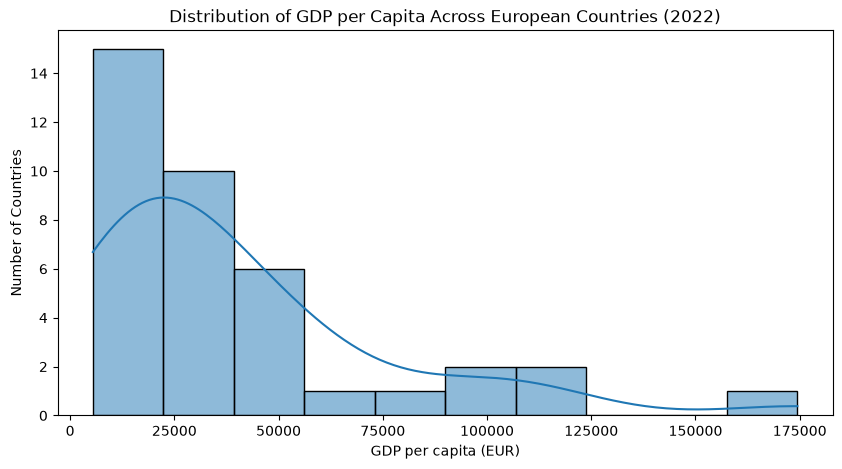

In [402]:
# Visualise the distribution of GDP per capita
plt.figure(figsize=(10, 5))

sns.histplot(
    data=gdp_countries,
    x="gdp_per_capita",
    bins=10,
    kde=True
)

plt.title("Distribution of GDP per Capita Across European Countries (2022)")
plt.xlabel("GDP per capita (EUR)")
plt.ylabel("Number of Countries")

plt.show()

The histogram shows a strongly right-skewed distribution of GDP per capita across the 38 selected countries.

Most observations are concentrated below €50,000 per capita, while a smaller number of countries have substantially higher values, extending beyond €100,000.

This distribution explains why the mean (€40,134.21) is considerably higher than the median (€27,170). A relatively small number of countries with high GDP per capita values pull the average upwards.

The histogram suggests considerable economic variation across the selected countries and highlights the presence of potentially influential high-value observations.

#### GDP per Capita Boxplot

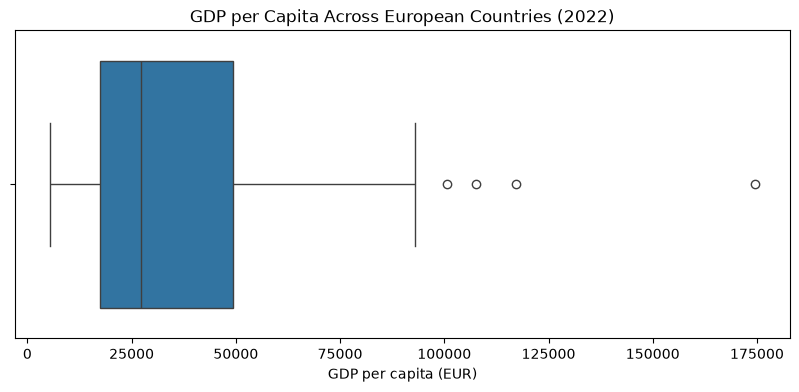

In [403]:
# Visualise GDP per capita using a boxplot
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=gdp_countries,
    x="gdp_per_capita"
)

plt.title("GDP per Capita Across European Countries (2022)")
plt.xlabel("GDP per capita (EUR)")

plt.show()

The boxplot provides a visual summary of the distribution of GDP per capita across the selected countries.

The median is €27,170, while the middle 50% of observations range from €17,525 to €49,380.

The distribution shows several observations above the upper whisker, indicating potential statistical outliers. These values are substantially higher than those of most other countries and contribute to the right-skewed distribution.

The outlier classification is based on the 1.5 × IQR rule. However, statistical outliers are not necessarily incorrect observations and should not automatically be removed.

Further investigation is needed to identify the countries responsible for these values and understand their potential influence on the analysis.

#### Investigation of Statistical Outliers

In [404]:
# Identify statistical outliers using the IQR method

Q1 = gdp_countries["gdp_per_capita"].quantile(0.25)
Q3 = gdp_countries["gdp_per_capita"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

outliers = gdp_countries[
    (gdp_countries["gdp_per_capita"] < lower_bound) |
    (gdp_countries["gdp_per_capita"] > upper_bound)
]

outliers

,geo,gdp_per_capita,status
12,IE,100630,NaN
21,LU,117100,NaN
34,LI,174440,NaN
35,NO,107660,NaN


The IQR method identified four countries with GDP per capita values above the upper outlier boundary:

- Ireland: €100,630
- Luxembourg: €117,100
- Liechtenstein: €174,440
- Norway: €107,660

These observations are substantially higher than the values recorded for most other countries in the dataset.

None of these observations contains an additional Eurostat data quality flag. Therefore, they will be retained in the dataset rather than removed solely because they are statistical outliers.

Their influence on the distribution and subsequent statistical analysis will be considered when interpreting the results.

# 4. Data Cleaning and Validation

## 4.1 Restrict WHO Observations to the European Region

The WHO dataset contains country-level observations from around the world. However, our research focuses on European countries.

Before integrating the datasets, we need to restrict the WHO observations to the European geographical scope.

We will first inspect the geographical classifications provided by WHO to understand how countries are assigned to regions. This will help us apply a consistent geographical filter without relying on assumptions about country codes.


In [405]:
# Inspect the geographical regions represented in the WHO dataset
who_2022_adults["ParentLocation"].value_counts(dropna=False)

ParentLocation
Europe                   52
Africa                   47
Americas                 36
Western Pacific          28
Eastern Mediterranean    22
South-East Asia          10
Name: count, dtype: int64

In [406]:
# Filter WHO observations to the European Region
who_europe = who_2022_adults[
    who_2022_adults["ParentLocation"] == "Europe"
].copy()

# Inspect the resulting dataset
print("European observations:", who_europe.shape[0])
print("Unique countries:", who_europe["SpatialDim"].nunique())

who_europe[["SpatialDim", "ParentLocation", "NumericValue"]].head()

European observations: 52
Unique countries: 52


,SpatialDim,ParentLocation,NumericValue
27186,HUN,Europe,29.413515
27690,TUR,Europe,44.388168
28330,KAZ,Europe,28.229771
28569,GRC,Europe,35.195946
28618,CZE,Europe,23.366205


In [407]:
# List all countries included in the WHO European Region
sorted(who_europe["SpatialDim"].unique())

['ALB',
 'AND',
 'ARM',
 'AUT',
 'AZE',
 'BEL',
 'BGR',
 'BIH',
 'BLR',
 'CHE',
 'CYP',
 'CZE',
 'DEU',
 'DNK',
 'ESP',
 'EST',
 'FIN',
 'FRA',
 'GBR',
 'GEO',
 'GRC',
 'HRV',
 'HUN',
 'IRL',
 'ISL',
 'ISR',
 'ITA',
 'KAZ',
 'KGZ',
 'LTU',
 'LUX',
 'LVA',
 'MDA',
 'MKD',
 'MLT',
 'MNE',
 'NLD',
 'NOR',
 'POL',
 'PRT',
 'ROU',
 'RUS',
 'SMR',
 'SRB',
 'SVK',
 'SVN',
 'SWE',
 'TJK',
 'TKM',
 'TUR',
 'UKR',
 'UZB']

## 4.2 Standardise geographical identifiers

In [408]:
# Convert WHO alpha-3 country codes to ISO alpha-2 codes
who_europe["geo"] = who_europe["SpatialDim"].apply(
    lambda code: pycountry.countries.get(alpha_3=code).alpha_2
    if pycountry.countries.get(alpha_3=code)
    else None
)

# Inspect the mapping
who_europe[["SpatialDim", "geo"]].sort_values("SpatialDim")

,SpatialDim,geo
37786,ALB,AL
28738,AND,AD
28977,ARM,AM
31450,AUT,AT
33048,AZE,AZ
33708,BEL,BE
37666,BGR,BG
33100,BIH,BA
38146,BLR,BY
40879,CHE,CH


### Aligning Country-Code Conventions

The `pycountry` package converts WHO's ISO alpha-3 identifiers into standard ISO alpha-2 country codes.

However, Eurostat uses `EL` for Greece, whereas the standard ISO alpha-2 code is `GR`. To ensure consistency across the datasets, this identifier must be adjusted to match Eurostat's geographical coding convention.

This adjustment is applied before comparing geographical coverage.

In [409]:
# Align Greece's country code with Eurostat's convention
who_europe.loc[who_europe["SpatialDim"] == "GRC", "geo"] = "EL"

# Verify the correction
who_europe.loc[
    who_europe["SpatialDim"] == "GRC",
    ["SpatialDim", "geo"]
]

,SpatialDim,geo
28569,GRC,EL


In [415]:
# Validate country-code conversion
print("Total WHO observations:", len(who_europe))
print("Missing country codes:", who_europe["geo"].isna().sum())
print("Unique Eurostat codes:", who_europe["geo"].nunique())
print("Duplicate Eurostat codes:", who_europe["geo"].duplicated().sum())

Total WHO observations: 52
Missing country codes: 0
Unique Eurostat codes: 52
Duplicate Eurostat codes: 0


## 4.3 Comparing Geographical Coverage Across Datasets

Before integrating the three datasets, their geographical coverage must be examined to identify countries with complete and comparable observations.

Although all datasets contain country-level data, they do not cover exactly the same set of countries. The WHO dataset covers 52 countries classified within its European Region, while the Eurostat obesity and GDP datasets contain 35 and 38 country observations, respectively.

To assess the extent of overlap, country identifiers are compared across the three datasets. This allows us to identify countries with complete data for all research variables, as well as geographical coverage gaps that may affect the final analytical sample.

The comparison also accounts for differences in country-code conventions between data providers, ensuring that equivalent countries are correctly matched.

In [411]:
# Extract unique country codes from each dataset
who_countries = set(who_europe["geo"])
obesity_country_codes = set(obesity_countries["geo"])
gdp_country_codes = set(gdp_countries["geo"])

# Compare dataset coverage
print("WHO countries:", len(who_countries))
print("Obesity countries:", len(obesity_country_codes))
print("GDP countries:", len(gdp_country_codes))

WHO countries: 52
Obesity countries: 35
GDP countries: 38


In [412]:
# Countries available in all three datasets
common_countries = (
    who_countries
    & obesity_country_codes
    & gdp_country_codes
)

print("Countries available in all three datasets:", len(common_countries))
print(sorted(common_countries))

Countries available in all three datasets: 35
['AL', 'AT', 'BA', 'BE', 'BG', 'CH', 'CY', 'CZ', 'DK', 'EE', 'EL', 'ES', 'FI', 'FR', 'HR', 'HU', 'IE', 'IS', 'IT', 'LT', 'LU', 'LV', 'ME', 'MK', 'MT', 'NL', 'NO', 'PL', 'PT', 'RO', 'RS', 'SE', 'SI', 'SK', 'TR']


### 4.3.1 Identify Geographical Coverage Gaps

In [413]:
# Countries missing from each dataset relative to the WHO European Region
missing_obesity = who_countries - obesity_country_codes
missing_gdp = who_countries - gdp_country_codes

# Countries available in obesity and GDP, but not in WHO's European subset
obesity_outside_who = obesity_country_codes - who_countries
gdp_outside_who = gdp_country_codes - who_countries

print("Missing from obesity:", len(missing_obesity))
print(sorted(missing_obesity))

print("\nMissing from GDP:", len(missing_gdp))
print(sorted(missing_gdp))

print("\nObesity countries outside WHO:", len(obesity_outside_who))
print(sorted(obesity_outside_who))

print("\nGDP countries outside WHO:", len(gdp_outside_who))
print(sorted(gdp_outside_who))

Missing from obesity: 17
['AD', 'AM', 'AZ', 'BY', 'DE', 'GB', 'GE', 'IL', 'KG', 'KZ', 'MD', 'RU', 'SM', 'TJ', 'TM', 'UA', 'UZ']

Missing from GDP: 15
['AD', 'AM', 'AZ', 'BY', 'GB', 'GE', 'IL', 'KG', 'KZ', 'RU', 'SM', 'TJ', 'TM', 'UA', 'UZ']

Obesity countries outside WHO: 0
[]

GDP countries outside WHO: 1
['LI']


### 4.3.2 Geographical Coverage Assessment

The comparison of geographical coverage identified differences in the availability of country-level observations across the three datasets.

The WHO dataset contains 52 countries classified within its European Region. The Eurostat obesity dataset contains 35 countries, all of which are represented in the WHO dataset. The GDP dataset contains 38 countries, of which 37 overlap with the WHO geographical coverage. Liechtenstein is the only GDP observation outside the selected WHO region.

After standardising country identifiers and accounting for differences in geographical coding conventions, the intersection of all three datasets consists of 35 countries.

These countries have corresponding observations for physical inactivity, obesity prevalence and GDP per capita, making them suitable candidates for the common analytical sample.

The differences in coverage reflect the geographical scope and data availability of the selected sources. The analysis will therefore focus on the common set of countries to ensure consistent comparisons across all three variables.

## 4.4 Validate analytical variables

After assessing geographical coverage, the next step is to validate the analytical variables that will be used in the statistical analysis.

Although initial data quality checks were performed during the preparation of each individual dataset, these variables require further validation before integration.

The validation focuses on data types, missing values, reasonable value ranges and the uniqueness of country-level observations. This helps ensure that the datasets are suitable for comparison and subsequent statistical analysis.

### 4.4.1 Inspect data types and missing values

In [416]:
# Inspect analytical variables across all three datasets

print("WHO Physical Inactivity")
print("Data type:", who_europe["NumericValue"].dtype)
print("Missing values:", who_europe["NumericValue"].isna().sum())

print("\nEurostat Obesity")
print("Data type:", obesity_countries["obesity_pct"].dtype)
print("Missing values:", obesity_countries["obesity_pct"].isna().sum())

print("\nEurostat GDP per Capita")
print("Data type:", gdp_countries["gdp_per_capita"].dtype)
print("Missing values:", gdp_countries["gdp_per_capita"].isna().sum())

WHO Physical Inactivity
Data type: float64
Missing values: 0

Eurostat Obesity
Data type: float64
Missing values: 0

Eurostat GDP per Capita
Data type: int64
Missing values: 0


### 4.4.2 Explicit range validation

In [418]:
# Validate expected value ranges

print("WHO Physical Inactivity")
print(
    "All values between 0 and 100:",
    who_europe["NumericValue"].between(0, 100).all()
)

print("\nEurostat Obesity")
print(
    "All values between 0 and 100:",
    obesity_countries["obesity_pct"].between(0, 100).all()
)

print("\nEurostat GDP per Capita")
print(
    "All values greater than 0:",
    (gdp_countries["gdp_per_capita"] > 0).all()
)

WHO Physical Inactivity
All values between 0 and 100: True

Eurostat Obesity
All values between 0 and 100: True

Eurostat GDP per Capita
All values greater than 0: True


### 4.4.3 Check duplicate country observations

In [419]:
# Check for duplicate country identifiers

print("WHO duplicate countries:", who_europe["geo"].duplicated().sum())

print("Obesity duplicate countries:", obesity_countries["geo"].duplicated().sum())

print("GDP duplicate countries:", gdp_countries["geo"].duplicated().sum())

WHO duplicate countries: 0
Obesity duplicate countries: 0
GDP duplicate countries: 0


### 4.4.4 Analytical Variable Validation Summary

The validation checks confirmed that all three datasets contain appropriately formatted analytical variables, with no missing values, invalid ranges or duplicate country identifiers.

The physical inactivity and obesity variables contain valid percentage values between 0 and 100, while all GDP per capita observations are positive.

The datasets therefore pass the analytical variable validation checks and can proceed to the preparation of the common analytical sample.

## 4.5 Establish the final analytical sample

Following geographical and analytical variable validation, the three datasets are restricted to the 35 countries with complete geographical coverage across all research variables.

Using a common set of countries ensures that subsequent comparisons and statistical analyses are based on consistent observations.

# 5. Data Integration

Merge the three datasets.

Validate the merged DataFrame.

Check that each row represents one country.

Prepare the final analytical dataset.